# From batman to pizzetti in one line: a TESS hot Jupiter with emcee

pizzetti has batman's interface. Code written for batman runs after changing one line:

```python
import pizzetti as batman
```

This notebook fits a synthetic TESS-like light curve of a hot Jupiter (quadratic limb darkening)
twice with [emcee](https://emcee.readthedocs.io): once with batman and once with pizzetti, using the same
likelihood, the same starting positions and the same random numbers. It compares the posteriors,
the model accuracy and the cost. Run time: about a minute.

The full-length runs of the paper (20 000 steps) are in `inference/`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner

import batman
import pizzetti

print("batman", batman.__version__, "| pizzetti", pizzetti.__version__, "| emcee", emcee.__version__)

batman 2.5.1 | pizzetti 0.2.0 | emcee 3.1.6


## Synthetic data

Seven transits at 2-min cadence, 500 ppm white noise. The noise-free model is computed with pizzetti's
Green's-theorem quadrature with the interior series switched off (accurate to ~1e-16), so that neither code
is favoured by the simulation.

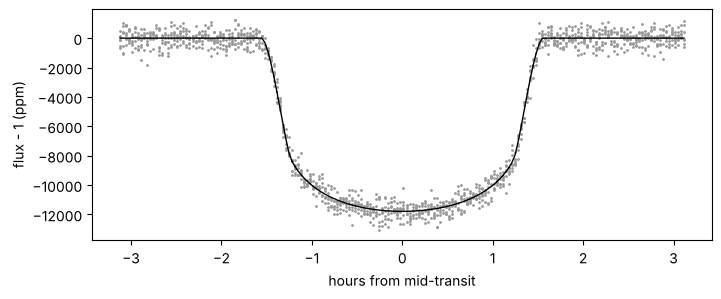

In [2]:
truth = dict(t0=0.0, per=3.5, rp=0.10, a=9.0, b=0.35, u1=0.40, u2=0.25)
sigma = 500e-6

epochs = np.arange(7)
t_one = np.arange(-0.13, 0.13, 2.0 / 1440)
t = (truth["t0"] + epochs[:, None] * truth["per"] + t_one[None, :]).ravel()

def params(module, t0, per, rp, a, b, u1, u2):
    p = module.TransitParams()
    p.t0, p.per, p.rp, p.a = t0, per, rp, a
    p.inc = np.degrees(np.arccos(b / a))
    p.ecc, p.w = 0.0, 90.0
    p.limb_dark, p.u = "quadratic", [u1, u2]
    return p

p_true = params(pizzetti, **truth)
f_true = pizzetti.TransitModel(p_true, t, series_tol=0.0, limb="quadrature").light_curve(p_true)
y = f_true + sigma * np.random.default_rng(42).standard_normal(t.size)

fold = (t - truth["t0"] + 0.5 * truth["per"]) % truth["per"] - 0.5 * truth["per"]
plt.figure(figsize=(8, 3))
plt.plot(24 * fold, 1e6 * (y - 1), ".", ms=2, color="0.6")
plt.plot(24 * np.sort(fold), 1e6 * (f_true[np.argsort(fold)] - 1), "k", lw=1)
plt.xlabel("hours from mid-transit"); plt.ylabel("flux - 1 (ppm)");

## The likelihood: identical for both codes

Sampling parameters: $t_0$, $P$, $R_p/R_\star$, $a/R_\star$, $b$ and the limb-darkening parameters
$q_1, q_2$ of Kipping (2013), all with uniform priors. The only difference between the two runs is the
module passed to `make_log_prob`.

In [3]:
names = ["t0", "per", "rp", "a", "b", "q1", "q2"]

def to_u(q1, q2):
    s = np.sqrt(q1)
    return 2 * s * q2, s * (1 - 2 * q2)

def make_log_prob(module):
    prm = params(module, **truth)
    model = module.TransitModel(prm, t)            # default settings of each package
    def log_prob(th):
        t0, per, rp, a, b, q1, q2 = th
        if not (0 < rp < 0.5 and 1.5 < a < 100 and 0 <= b < 1 + rp and 0 < q1 < 1 and 0 < q2 < 1):
            return -np.inf
        prm.t0, prm.per, prm.rp, prm.a = t0, per, rp, a
        prm.inc = np.degrees(np.arccos(b / a))
        prm.u = list(to_u(q1, q2))
        r = y - model.light_curve(prm)
        return -0.5 * np.dot(r, r) / sigma**2
    return log_prob

u1, u2 = truth["u1"], truth["u2"]
th0 = np.array([truth["t0"], truth["per"], truth["rp"], truth["a"], truth["b"], (u1 + u2)**2, u1 / (2 * (u1 + u2))])
nwalkers, nsteps = 32, 3000
p0 = th0 + np.array([2e-4, 2e-6, 1e-3, 0.05, 0.02, 0.02, 0.02]) * np.random.default_rng(1234).standard_normal((nwalkers, 7))

## Run emcee twice

In [4]:
chains, timing = {}, {}
for name, module in (("batman", batman), ("pizzetti", pizzetti)):
    log_prob = make_log_prob(module)
    log_prob(p0[0])                                     # warm-up (pizzetti compiles on first use)
    sampler = emcee.EnsembleSampler(nwalkers, 7, log_prob)
    sampler.random_state = np.random.RandomState(2024).get_state()   # identical proposals
    s = time.perf_counter()
    sampler.run_mcmc(p0, nsteps, progress=False)
    timing[name] = time.perf_counter() - s
    chains[name] = sampler.get_chain()
    print(f"{name:9s} {timing[name]:6.1f} s   acceptance {np.mean(sampler.acceptance_fraction):.3f}")
print(f"speed-up: {timing['batman'] / timing['pizzetti']:.1f}x")

batman      14.9 s   acceptance 0.411


pizzetti     4.3 s   acceptance 0.404
speed-up: 3.4x


## Posteriors

With identical proposals the two chains stay step-by-step identical until a difference between the models
changes one acceptance decision. After that they are independent samples of (nearly) the same posterior.

In [5]:
same = np.all(np.isclose(chains["batman"], chains["pizzetti"], rtol=1e-12, atol=0), axis=(1, 2))
print("chains identical for the first", np.argmin(same) if not same.all() else len(same), "steps")

burn = 1000
sb = chains["batman"][burn:].reshape(-1, 7)
sp = chains["pizzetti"][burn:].reshape(-1, 7)
print(f"{'':6s}{'batman':>24s}{'pizzetti':>24s}   difference/sigma")
for i, n in enumerate(names):
    qb, qp = np.percentile(sb[:, i], [16, 50, 84]), np.percentile(sp[:, i], [16, 50, 84])
    sig = 0.5 * (qb[2] - qb[0])
    print(f"{n:6s}{qb[1]:16.7g} ± {sig:.1e}{qp[1]:16.7g} ± {0.5*(qp[2]-qp[0]):.1e}   {(qp[1]-qb[1])/sig:+.3f}")

chains identical for the first 846 steps
                        batman                pizzetti   difference/sigma
t0       -0.0001467715 ± 1.1e-04   -0.0001380631 ± 1.1e-04   +0.076
per           3.500055 ± 3.1e-05        3.500051 ± 3.0e-05   -0.118
rp          0.09973779 ± 6.8e-04      0.09973457 ± 7.1e-04   -0.005
a             9.161093 ± 1.4e-01        9.157869 ± 1.4e-01   -0.023
b            0.3018844 ± 5.5e-02       0.3024552 ± 5.6e-02   +0.010
q1           0.3933587 ± 6.7e-02       0.3960747 ± 7.4e-02   +0.040
q2           0.3471787 ± 6.3e-02       0.3413301 ± 6.9e-02   -0.093


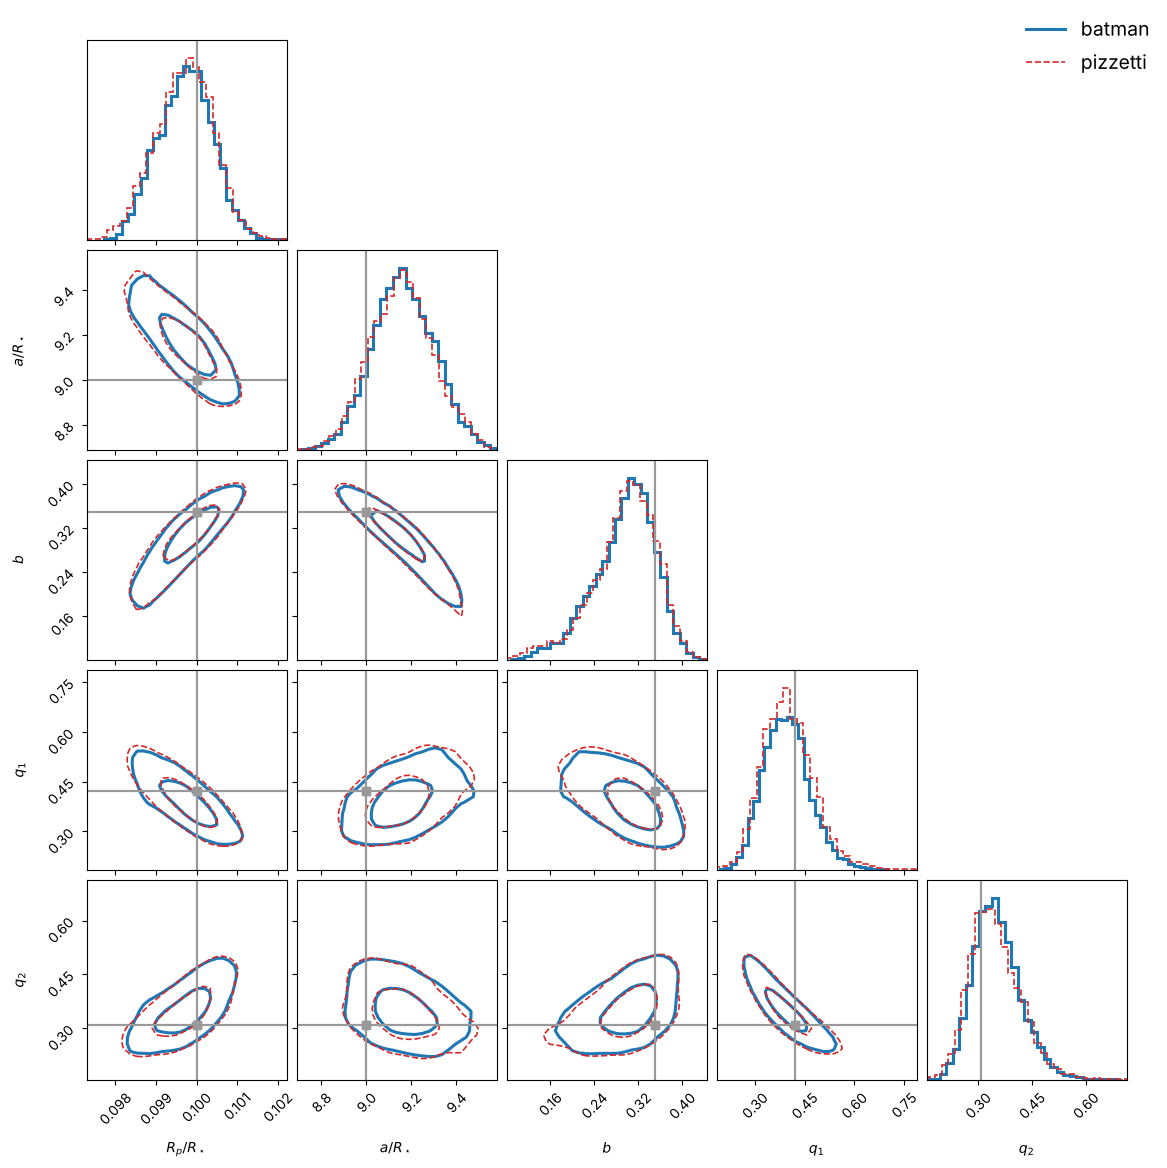

In [6]:
sel = [2, 3, 4, 5, 6]
labels = [r"$R_p/R_\star$", r"$a/R_\star$", r"$b$", r"$q_1$", r"$q_2$"]
kw = dict(labels=labels, bins=30, smooth=1.0, levels=(0.393, 0.865), plot_datapoints=False,
          plot_density=False, truths=th0[sel], truth_color="0.6")
fig = corner.corner(sb[:, sel], color="C0", hist_kwargs=dict(lw=2.2), contour_kwargs=dict(linewidths=2.2), **kw)
corner.corner(sp[:, sel], fig=fig, color="C3", hist_kwargs=dict(lw=1.2, ls="--"),
              contour_kwargs=dict(linewidths=1.2, linestyles="--"), **kw)
fig.legend(handles=[plt.Line2D([], [], color="C0", lw=2.2, label="batman"),
                    plt.Line2D([], [], color="C3", lw=1.2, ls="--", label="pizzetti")],
           loc="upper right", fontsize=14, frameon=False);

## Accuracy of the two models

Both models are compared with the reference (quadrature, series off) at 100 posterior samples.

In [7]:
ref_prm = params(pizzetti, **truth)
ref = pizzetti.TransitModel(ref_prm, t, series_tol=0.0, limb="quadrature")
mods = {n: (params(m, **truth), None) for n, m in (("batman", batman), ("pizzetti", pizzetti))}
mods = {n: (prm, m.TransitModel(prm, t)) for (n, (prm, _)), m in zip(mods.items(), (batman, pizzetti))}
err = {"batman": 0.0, "pizzetti": 0.0}
for th in sp[np.random.default_rng(0).choice(len(sp), 100, replace=False)]:
    t0, per, rp, a, b, q1, q2 = th
    for prm in [ref_prm] + [v[0] for v in mods.values()]:
        prm.t0, prm.per, prm.rp, prm.a = t0, per, rp, a
        prm.inc = np.degrees(np.arccos(b / a)); prm.u = list(to_u(q1, q2))
    fr = ref.light_curve(ref_prm)
    for n, (prm, m) in mods.items():
        err[n] = max(err[n], np.max(np.abs(m.light_curve(prm) - fr)))
for n, e in err.items():
    print(f"{n:9s} largest model error over the posterior: {e:.1e}  ({e / sigma:.1e} of the noise)")

batman    largest model error over the posterior: 9.0e-09  (1.8e-05 of the noise)
pizzetti  largest model error over the posterior: 7.2e-10  (1.4e-06 of the noise)


## Summary

* The posteriors agree to a small fraction of their width; the remaining differences are Monte Carlo noise
  (they shrink with longer chains, see `inference/` for 20 000-step runs).
* pizzetti's model error is below its proven tolerance of 1e-9; batman's analytic quadratic law is accurate
  to ~1e-8.
* The fit is about twice as fast with pizzetti. For the quadratic law, most in-transit samples use the
  interior series (one square root, one division and a dozen multiply-adds per sample).